# 05 - Feature Engineering
**Feature engineering** = creating new input columns from existing ones so that patterns become easier for a model to learn.
Golden rule: a feature may only use information that is **available at the moment we want to predict** — never the answer (target) or anything recorded after the failure.

In [1]:
# Import the libraries used in this notebook
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append("..")          # lets us import our own src/ package
from src import preprocessing as pp

np.random.seed(42)             # fixed seed for reproducibility
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

In [2]:
df = pd.read_csv("../data/processed/cleaned_data.csv")
print(df.shape)

(10000, 14)


## Features created
| Feature | Formula | Why |
|---|---|---|
| `temp_diff_K` | process temp − air temp | Small gap → poor heat dissipation (HDF) |
| `temp_ratio` | process temp / air temp | Kelvin is an absolute scale (always > 0), so the ratio is physically meaningful and cannot divide by zero |
| `torque_x_rpm` | torque × rpm | Raw mechanical-power proxy (units Nm·rpm — not watts) |
| `power_W` | torque × rpm × 2π/60 | Proper mechanical power in watts (rpm converted to rad/s) |
| `tool_wear_band` | bins 0-50, 51-100, 101-150, 151-200, 200+ | Equal 50-min bands; EDA showed the risk jump after 200 min |

In [3]:
# Numerical safety check before computing the ratio
print("Minimum air temperature (K):", df["Air temperature [K]"].min())
eng = pp.add_engineered_features(df)
eng[["temp_diff_K", "temp_ratio", "torque_x_rpm", "power_W", "tool_wear_band"]].describe(include="all").T

Minimum air temperature (K): 295.3


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
temp_diff_K,10000.0,NaN,NaN,NaN,10.00063,1.001094,7.6,9.3,9.8,11.0,12.1
temp_ratio,10000.0,NaN,NaN,NaN,1.033352,0.003492,1.025116,1.030686,1.032847,1.036777,1.040672
torque_x_rpm,10000.0,NaN,NaN,NaN,59967.14704,10193.093881,10966.8,53105.4,59883.9,66873.75,99980.4
power_W,10000.0,NaN,NaN,NaN,6279.744953,1067.418295,1148.44061,5561.184484,6271.027344,7003.002724,10469.923005
tool_wear_band,10000,5,0-50,2396,NaN,NaN,NaN,NaN,NaN,NaN,NaN


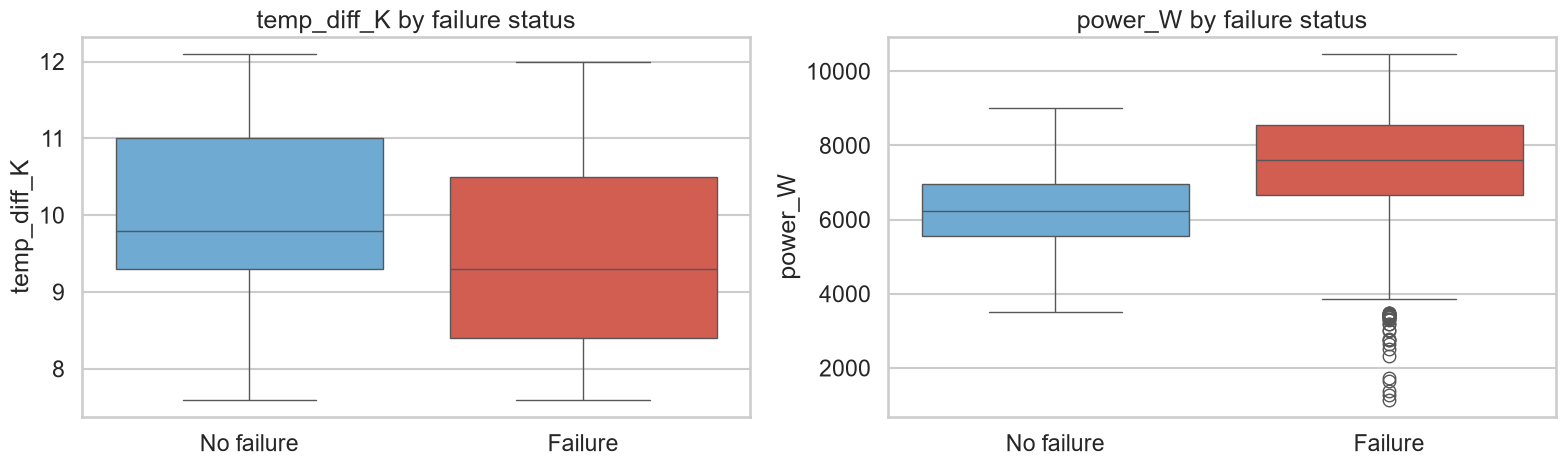

,temp_diff_K,power_W
Machine failure,,
0,9.8,6243.046225
1,9.3,7611.429737


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, ["temp_diff_K", "power_W"]):
    sns.boxplot(data=eng, x=pp.TARGET_COL, y=col, hue=pp.TARGET_COL, ax=ax, palette=["#5dade2", "#e74c3c"], legend=False)
    ax.set_title(f"{col} by failure status"); ax.set_xticks([0, 1], ["No failure", "Failure"]); ax.set_xlabel("")
plt.tight_layout(); plt.show()
eng.groupby(pp.TARGET_COL)[["temp_diff_K", "power_W"]].median()

In [5]:
band_rate = eng.groupby("tool_wear_band", observed=True)[pp.TARGET_COL].agg(["count", "mean"])
band_rate["failure_%"] = (band_rate["mean"] * 100).round(2)
band_rate

,count,mean,failure_%
tool_wear_band,,,
0-50,2396,0.021703,2.17
51-100,2271,0.023338,2.33
101-150,2295,0.021786,2.18
151-200,2276,0.028998,2.90
200+,762,0.154856,15.49


**Observed:** failures have a smaller median temperature gap and a higher median power, and failure power values are much more spread out (both very low and very high power).
The 200+ tool-wear band has a much higher failure rate. These features are kept for Level 2. (We only *describe* them here — the target is used for checking, never to build the features.)

## Sequential features (lag / rolling / rate-of-change)

In [6]:
print("Timestamp column present:", any("time" in c.lower() or "date" in c.lower() for c in df.columns))
print("Repeated Product IDs:", df["Product ID"].duplicated().sum())

Timestamp column present: False
Repeated Product IDs: 0


There is **no timestamp** and **no machine is observed more than once**. `UDI` is only a row index.
Therefore lag, rolling mean/std, rate-of-change and historical failure-count features would be **invented sequences** and are **not created**.
These features would become possible with a true time-series dataset such as NASA C-MAPSS.

## Feature columns vs excluded columns

In [7]:
features = pp.model_feature_columns()
print("✅ Model input features:")
for f in features: print("  -", f)
print("\n🎯 Target:", pp.TARGET_COL)
print("\n❌ Excluded from model inputs:")
for c, why in pp.excluded_columns().items(): print(f"  - {c}: {why}")

✅ Model input features:
  - Type
  - Air temperature [K]
  - Process temperature [K]
  - Rotational speed [rpm]
  - Torque [Nm]
  - Tool wear [min]
  - temp_diff_K
  - temp_ratio
  - torque_x_rpm
  - power_W
  - tool_wear_band

🎯 Target: Machine failure

❌ Excluded from model inputs:
  - UDI: Row identifier - no physical meaning
  - Product ID: Identifier; its first letter duplicates 'Type'
  - Machine failure: Target variable
  - TWF: Failure-mode label (post-event, leaks the target)
  - HDF: Failure-mode label (post-event, leaks the target)
  - PWF: Failure-mode label (post-event, leaks the target)
  - OSF: Failure-mode label (post-event, leaks the target)
  - RNF: Failure-mode label (post-event, leaks the target)


## Leakage check
- Failure modes `TWF, HDF, PWF, OSF, RNF` are recorded **after** a failure and almost perfectly reveal the target → excluded.
- No feature was computed from the target.
- No scaling/encoding statistics are fitted yet — in Level 2 they must be fitted on the **training split only**.

In [8]:
# Automatic leakage guard: no feature column may be the target or a failure mode
assert not set(features) & ({pp.TARGET_COL} | set(pp.FAILURE_MODE_COLS)), "Leakage!"
print("Leakage guard passed ✅")

from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
eng.to_csv("../data/processed/engineered_data.csv", index=False)
check = pd.read_csv("../data/processed/engineered_data.csv")
print("Saved engineered_data.csv:", check.shape)
print(list(check.columns))

Leakage guard passed ✅
Saved engineered_data.csv: (10000, 19)
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'temp_diff_K', 'temp_ratio', 'torque_x_rpm', 'power_W', 'tool_wear_band']


## Summary
- 5 new features created; all use only process variables.
- Target and failure-mode columns are kept **in the file** (needed later for labels/analysis) but listed as **excluded** from model inputs.
- The engineered dataset is ready for Level 2 (classification), where train/test splitting must happen **before** any fitted preprocessing.